# GB AI — Evaluation of the trained model

This notebook re-runs the **evaluation** of the trained GB AI prototype. It does not retrain anything: it loads the saved model and the prepared ETHZ test windows from Google Drive (produced by `GB_AI_Prototype_Colab.ipynb`).

Note: the original training run (11 epochs on a Colab CPU) was not saved with its outputs, so this notebook reproduces the reported results from the saved model.

**Needs in Google Drive, folder `GB_AI`:** `gb_ai.keras`, `baseline_cnn.keras`, `gbai_windows_30s.npz`.

In [1]:
import os, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from tqdm.auto import tqdm

from google.colab import drive
drive.mount("/content/drive")
SAVE_DIR = "/content/drive/MyDrive/GB_AI"
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "none (CPU)")

Mounted at /content/drive
TensorFlow 2.21.0 | GPU: none (CPU)


## 1. Load data and models

In [2]:
SR, WIN_SEC = 100, 30
WIN = SR * WIN_SEC

def mag_loss(y_true, y_pred):  # same loss as in training, needed to load the model
    m, mask = y_true[:, 0], y_true[:, 1]
    mu, logvar = y_pred[:, 0], tf.clip_by_value(y_pred[:, 1], -6.0, 6.0)
    return mask * (0.5 * tf.abs(m - mu) + 0.3 * 0.5 * (tf.exp(-logvar) * tf.square(m - mu) + logvar))

d = np.load(f"{SAVE_DIR}/gbai_windows_{WIN_SEC}s.npz")
X_test, y_test, m_test = d["X_test"].astype(np.float32), d["y_test"], d["m_test"]
demo_X, demo_m = d["demo_X"], d["demo_m"]
print(f"Test windows: {len(y_test)} (earthquake {int(y_test.sum())}, noise {int((y_test==0).sum())}) | demo recordings: {len(demo_X)}")

gbai = keras.models.load_model(f"{SAVE_DIR}/gb_ai.keras", custom_objects={"mag_loss": mag_loss}, compile=False)
baseline = keras.models.load_model(f"{SAVE_DIR}/baseline_cnn.keras", compile=False)
gbai.summary()
print("GB AI trainable parameters:", f"{sum(int(np.prod(w.shape)) for w in gbai.trainable_weights):,}")

Test windows: 3664 (earthquake 1832, noise 1832) | demo recordings: 200


Model: "gb_ai"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 3000, 3)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 1500, 32)  │        512 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1500, 32)  │        128 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 1500, 32)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 750, 32)   │          0 │ re_lu_3[0][0]     │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 750, 64)   │     10,304 │ max_pooling1d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 750, 64)   │        256 │ conv1d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_4 (ReLU)      │ (None, 750, 64)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_4     │ (None, 375, 64)   │          0 │ re_lu_4[0][0]     │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 375, 128)  │     24,704 │ max_pooling1d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 375, 128)  │        512 │ conv1d_5[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_5 (ReLU)      │ (None, 375, 128)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_5     │ (None, 187, 128)  │          0 │ re_lu_5[0][0]     │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 187, 512)  │    788,480 │ max_pooling1d_5[… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 187, 512)  │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 187, 64)   │     32,832 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 187, 1)    │         65 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ softmax (Softmax)   │ (None, 187, 1)    │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dot (Dot)           │ (None, 1, 512)    │          0 │ softmax[0][0],    │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 512)       │          0 │ dot[0][0]         │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 859,332 (3.28 MB)

 Trainable params: 858,884 (3.28 MB)

 Non-trainable params: 448 (1.75 KB)

GB AI trainable parameters: 858,884


## 2. Detection and magnitude results on the held-out test set

                 Baseline CNN  GB AI
Accuracy                95.6%  98.1%
Precision               97.5%  98.6%
Recall                  93.6%  97.5%
F1                      95.5%  98.1%
False-alarm rate         2.4%   1.4%

Magnitude MAE (all): 0.35
  M < 2: MAE = 0.28 (n = 664)
  M 2-3: MAE = 0.31 (n = 907)
  M 3-4: MAE = 0.63 (n = 226)
  M >= 4: MAE = 1.02 (n = 35)


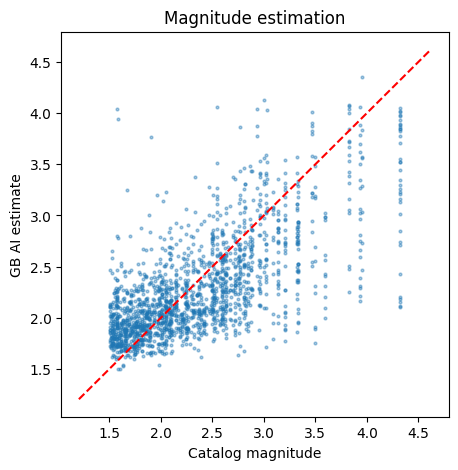

In [3]:
def det_metrics(y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0), "F1": f1_score(y_true, pred, zero_division=0),
            "False-alarm rate": fp / max(fp + tn, 1)}

prob_b = baseline.predict(X_test, batch_size=256, verbose=0).ravel()
out_g = gbai.predict(X_test, batch_size=256, verbose=0)
prob_g, mag_pred = out_g[0].ravel(), out_g[1]
results = pd.DataFrame({"Baseline CNN": det_metrics(y_test, prob_b), "GB AI": det_metrics(y_test, prob_g)})
print(results.map(lambda v: f"{v*100:.1f}%"))

ok = (y_test == 1) & np.isfinite(m_test)
mu_test = mag_pred[ok, 0]
err = np.abs(mu_test - m_test[ok])
print(f"\nMagnitude MAE (all): {err.mean():.2f}")
for lo, hi, name in [(-9, 2, "M < 2"), (2, 3, "M 2-3"), (3, 4, "M 3-4"), (4, 10, "M >= 4")]:
    sel = (m_test[ok] >= lo) & (m_test[ok] < hi)
    if sel.sum():
        print(f"  {name}: MAE = {err[sel].mean():.2f} (n = {sel.sum()})")

plt.figure(figsize=(5, 5))
plt.scatter(m_test[ok], mu_test, s=4, alpha=0.4)
lim = [np.nanmin(m_test[ok]) - 0.3, np.nanmax(m_test[ok]) + 0.3]
plt.plot(lim, lim, "r--"); plt.xlabel("Catalog magnitude"); plt.ylabel("GB AI estimate"); plt.title("Magnitude estimation")
plt.show()

## 3. Inference time (compiled graph, as in the live dashboard)

In [4]:
@tf.function(input_signature=[tf.TensorSpec((1, WIN, 3), tf.float32)])
def predict_one(x):
    return gbai(x, training=False)

x = tf.constant(X_test[:1])
for _ in range(3): predict_one(x)[0].numpy()
t0 = time.perf_counter()
for _ in range(100): predict_one(x)[0].numpy()  # .numpy() waits for the result
print(f"GB AI inference: {(time.perf_counter() - t0) / 100 * 1000:.1f} ms per window on this Colab runtime")

GB AI inference: 62.7 ms per window on this Colab runtime


## 4. Replayed real-time test (200 recordings, window moved every 0.1 s)

replay:   0%|          | 0/200 [00:00<?, ?it/s]

Recordings: 200 | detected: 99.5% | within 3 s: 99.5%
Median detection time: 0.20 s after P-wave | mean: 0.31 s
Recordings with an alert before the P-wave: 9 (4.5%)


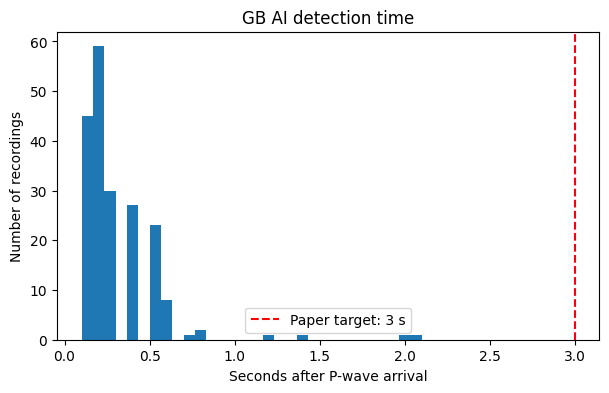

In [5]:
POST = 15 * SR
P_IDX = demo_X.shape[2] - POST
STEP, THR = int(0.1 * SR), 0.5

def normalize(w):
    w = w - w.mean(axis=1, keepdims=True)
    w = w / (w.std(axis=1, keepdims=True) + 1e-8)
    return w.T.astype(np.float32)

def sliding_probs(seg):
    ends = np.arange(P_IDX - 10 * SR, P_IDX + POST + 1, STEP)
    wins = np.stack([normalize(seg[:, e - WIN:e]) for e in ends])
    p = gbai.predict(wins, batch_size=256, verbose=0)[0].ravel()
    return (ends - P_IDX) / SR, p

delays, early = [], 0
for seg in tqdm(demo_X, desc="replay"):
    tt, pp = sliding_probs(seg)
    if (pp[tt < 0] >= THR).any():
        early += 1
    hit = np.where((tt >= 0) & (pp >= THR))[0]
    delays.append(tt[hit[0]] if len(hit) else np.nan)
delays = np.array(delays)
print(f"Recordings: {len(delays)} | detected: {np.isfinite(delays).mean()*100:.1f}% | within 3 s: {(delays <= 3).mean()*100:.1f}%")
print(f"Median detection time: {np.nanmedian(delays):.2f} s after P-wave | mean: {np.nanmean(delays):.2f} s")
print(f"Recordings with an alert before the P-wave: {early} ({early/len(delays)*100:.1f}%)")

plt.figure(figsize=(7, 4))
plt.hist(delays[np.isfinite(delays)], bins=30)
plt.axvline(3, color="r", ls="--", label="Paper target: 3 s")
plt.xlabel("Seconds after P-wave arrival"); plt.ylabel("Number of recordings"); plt.title("GB AI detection time"); plt.legend(); plt.show()

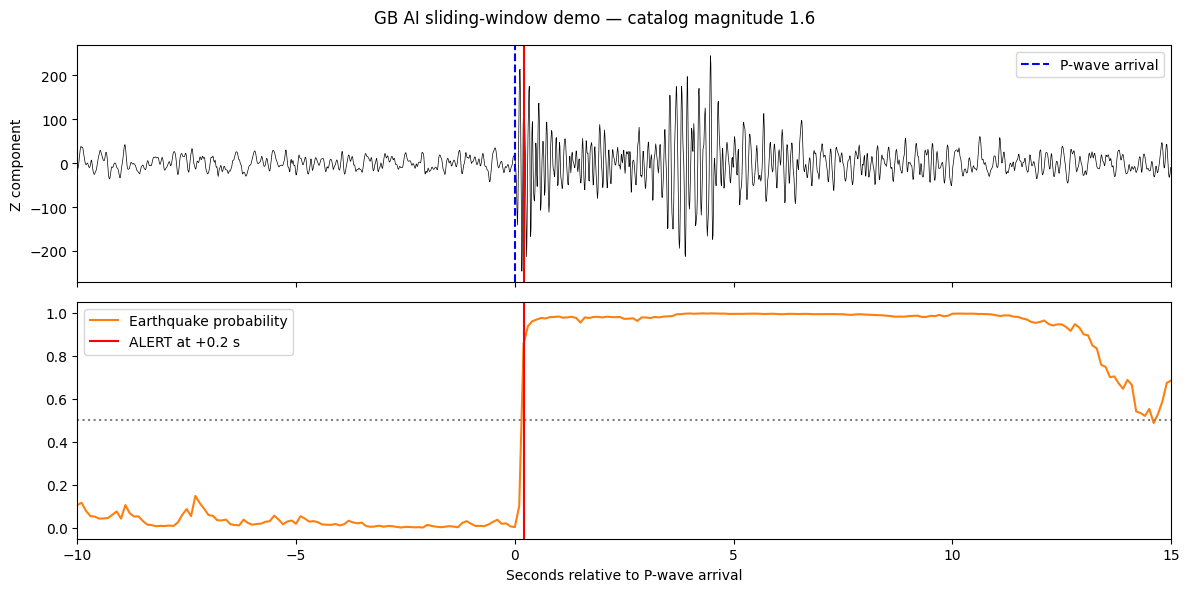

In [6]:
k = 0  # change to see another recording
seg = demo_X[k]
tt, pp = sliding_probs(seg)
t_full = (np.arange(seg.shape[1]) - P_IDX) / SR
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(t_full, seg[0], lw=0.5, color="k"); ax[0].axvline(0, color="b", ls="--", label="P-wave arrival")
ax[0].set_ylabel("Z component"); ax[0].legend()
ax[1].plot(tt, pp, color="tab:orange", label="Earthquake probability"); ax[1].axhline(THR, color="gray", ls=":")
alert = np.where((tt >= 0) & (pp >= THR))[0]
if len(alert):
    for a in ax: a.axvline(tt[alert[0]], color="r")
    ax[1].plot([], [], color="r", label=f"ALERT at +{tt[alert[0]]:.1f} s")
ax[1].set_xlim(-10, POST / SR); ax[1].set_ylim(-0.05, 1.05)
ax[1].set_xlabel("Seconds relative to P-wave arrival"); ax[1].legend()
plt.suptitle(f"GB AI sliding-window demo — catalog magnitude {demo_m[k]:.1f}"); plt.tight_layout(); plt.show()